In [1]:
TSN = 200157867
d = 67
alpha = 2
s = 8
h_bar, m, omega = 1, 1, 1

In [2]:
x_start = ((-1)**s)*(0.5+67/200)
print(x_start)

0.835


Problem A

In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
K_eps = np.zeros((601, 601), dtype = np.complex128);

def propagatorK (m, omega, h_bar, x_a, x_b, deltaT): #function for a single propagator
    C = np.sqrt((m * omega)/
         (2 * np.pi * 1j * h_bar * np.sin(omega*deltaT)))
    
    exp = (1j * m * omega)/(2 * h_bar * np.sin(omega * (deltaT))) * ((x_a ** 2+x_b ** 2) * np.cos(omega*(deltaT))- 2 * x_a * x_b)
    
    K = C * np.e ** exp
    return K
    
epsilon = 2 * np.pi/128;
deltax = 8/600;

for i in range(601):
    for k in range(601):
        x_a = -4 + i * deltax
        x_b = -4 + k * deltax
        
        K_eps[k, i] = propagatorK (1, 1, 1, x_a, x_b, epsilon)
                
K_8eps = deltax ** 7 * np.linalg.matrix_power(K_eps, 8)
print(K_8eps)
     

[[-0.05955846+0.0178667j  -0.0757611 +0.0217024j  -0.07967385+0.05414053j
  ... -0.46505982-0.30932634j -0.35439299-0.42735575j
  -0.21687407-0.50917202j]
 [-0.0757611 +0.0217024j  -0.0896081 +0.03330227j -0.08308486+0.06724787j
  ... -0.53404108-0.16837676j -0.46141968-0.31131639j
  -0.35439299-0.42735575j]
 [-0.07967385+0.05414053j -0.08308486+0.06724787j -0.06226964+0.09303051j
  ... -0.56407376-0.01040964j -0.53404108-0.16837676j
  -0.46505982-0.30932634j]
 ...
 [-0.46505982-0.30932634j -0.53404108-0.16837676j -0.56407376-0.01040964j
  ... -0.06226964+0.09303051j -0.08308486+0.06724787j
  -0.07967385+0.05414053j]
 [-0.35439299-0.42735575j -0.46141968-0.31131639j -0.53404108-0.16837676j
  ... -0.08308486+0.06724787j -0.0896081 +0.03330227j
  -0.0757611 +0.0217024j ]
 [-0.21687407-0.50917202j -0.35439299-0.42735575j -0.46505982-0.30932634j
  ... -0.07967385+0.05414053j -0.0757611 +0.0217024j
  -0.05955846+0.0178667j ]]


Problem B

In [5]:
def phi0 (x): #define wave-function of the electrons)
    C = (2 / np.pi) ** (1/4)
    exp = -1 * (x - x_start) ** 2
    phi0 = C * np.e ** exp
    return phi0

#find the initial wavefunction at each electron location 
#and record each electron location

inidense = np.zeros((601), dtype=np.complex128)
x_pos = np.zeros((601), dtype=np.complex128)
for i in range (601):
    x_e = -4 + i * deltax
    inidense[i] = phi0(x_e)
    x_pos[i] = x_e

In [6]:
#initialize needed arrays for plotting 
time = np.linspace(0, 2 * np.pi, 129)
ntdense = inidense.copy()
x_exp = np.zeros((129), dtype = np.float64)

In [7]:
#graph, evolve wavefunction one time step per loop

for n in range (129):
    #at t=n+1 timestep, expected value of x
    x_exp[n] = sum(deltax * x_pos * (np.abs(ntdense) ** 2))

    #propagated wavefunction by one timestep
    ntdense = deltax * K_eps @ ntdense   

/tmp/ipykernel_1332/281168409.py:5: ComplexWarning: Casting complex values to real discards the imaginary part
  x_exp[n] = sum(deltax * x_pos * (np.abs(ntdense) ** 2))


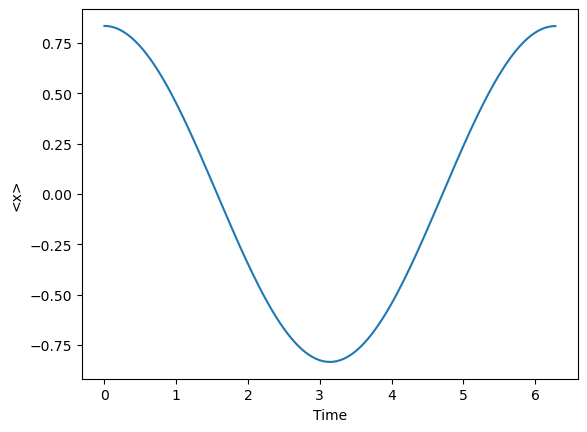

In [8]:
plt.plot(time, x_exp)
plt.xlabel("Time")
plt.ylabel("<x>")
plt.show()

Problem C

In [9]:
#initialize needed arrays for plotting 
ntdense = inidense.copy()
V = np.zeros((129), dtype = np.float64)
K = V.copy()
E = V.copy()

In [10]:
for n in range (129):

    #Potential 
    V[n] = sum(0.5 * deltax * (x_pos ** 2) * (np.abs(ntdense) ** 2))

    #Kinetic
    #Approximate the derivative of the propagated wavefunction 
    #at x_i by taking the slope between two points (x_i+1, x_i-1)
    der = np.gradient(ntdense, deltax)
    K[n] = h_bar ** 2 / 2 * sum(deltax * np.abs(der) ** 2)

    #Total energy
    E[n] = V[n] + K[n]

    #propagated wavefunction by one timestep
    ntdense = deltax * K_eps @ ntdense    

/tmp/ipykernel_1332/1752841684.py:4: ComplexWarning: Casting complex values to real discards the imaginary part
  V[n] = sum(0.5 * deltax * (x_pos ** 2) * (np.abs(ntdense) ** 2))


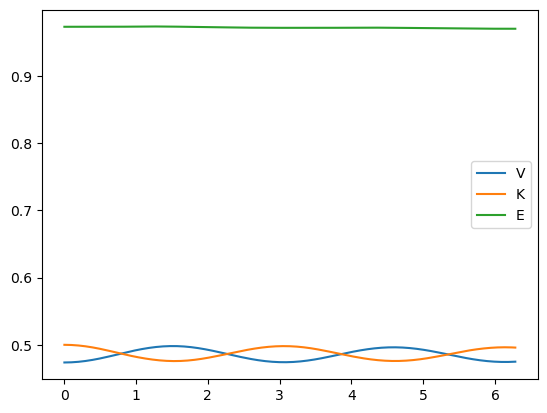

In [11]:
plt.plot(time, V, label = 'V')
plt.plot(time, K, label = 'K')
plt.plot(time, E, label = 'E')
plt.legend()

Problem D